# TTC Subway Delays: Which Lines and Causes Matter Most?

**Course:** INFO 5100 – Lab 8: Data Visualization
**Dataset:** [TTC Subway Delay Data](https://open.toronto.ca/dataset/ttc-subway-delay-data/) (City of Toronto Open Data), 2014 – Oct 2026

## 1. Introduction

**Python and why we use it.** Python is a general-purpose language that is widely used for data analysis, web development, automation and machine learning. With the **pandas** library we can load and clean large tables of data, and with **Matplotlib** and **Seaborn** we can turn them into charts.

**Why a virtual environment (conda)?** A virtual environment such as `info5100` keeps the exact Python version and libraries for this project separate from every other project on the computer, so the code runs the same way on another machine.

**Why a Jupyter notebook?** A notebook mixes explanations, code and the resulting charts in one document, so the analysis can be read, re-run and checked step by step.

**Why data visualization?** A table with hundreds of thousands of rows is hard to understand; a chart makes patterns (which line, which cause, which hour) visible at a glance.

**Question.** Using the TTC's recorded subway delays, *which lines have the most delays, what causes the most delay minutes, and when do delays happen?*

## 2. Setup
We import the libraries and define the folder paths. `pathlib` makes the paths relative to the project folder, so no path needs to be edited on another computer.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW_DIR = Path("data") / "raw"
CHART_DIR = Path("charts")
CHART_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# Names and TTC-inspired colours for the four subway lines
LINE_NAMES = {"YU": "Line 1 – Yonge-University", "BD": "Line 2 – Bloor-Danforth",
              "SRT": "Line 3 – Scarborough", "SHP": "Line 4 – Sheppard"}
LINE_COLORS = {"Line 1 – Yonge-University": "#E0A100", "Line 2 – Bloor-Danforth": "#00853E",
               "Line 3 – Scarborough": "#0072BC", "Line 4 – Sheppard": "#8E3B9E"}

## 3. Load the data
The delay data come as several Excel workbooks (2014–2024; some have one sheet per month) and one CSV file (2025 onward). We read every sheet of every workbook, read the CSV, and stack everything into one pandas DataFrame. The README and delay-code files in the same folder are *reference* tables, not incidents, so they are not included here (the codes file is used later to explain the delay codes).

In [2]:
excel_files = sorted(path for path in RAW_DIR.glob("ttc-subway-delay-*.xlsx")
                     if "readme" not in path.name and "codes" not in path.name)

tables = []
for path in excel_files:
    all_sheets = pd.read_excel(path, sheet_name=None)      # dictionary: sheet name -> DataFrame
    tables.extend(all_sheets.values())

csv_table = pd.read_csv(RAW_DIR / "TTC Subway Delay Data since 2025.csv").drop(columns="_id")
tables.append(csv_table)

df = pd.concat(tables, ignore_index=True)
print("Excel files read:", len(excel_files))
print("Combined table shape (rows, columns):", df.shape)

Excel files read: 9
Combined table shape (rows, columns): (273049, 10)


## 4. Explore the data
Each row is one recorded incident. The main columns are `Date`, `Time`, `Station`, `Code` (the delay cause), `Min Delay` (minutes of delay), `Min Gap` (minutes between trains) and `Line`.

In [3]:
display(df.head())
display(df.tail(3))
df.info()

,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,2018-01-01 00:00:00,00:29,Monday,SHEPPARD WEST STATION,MUATC,10,15,N,YU,5986
1,2018-01-01 00:00:00,01:07,Monday,DUNDAS STATION,MUNCA,0,0,NaN,YU,0
2,2018-01-01 00:00:00,01:22,Monday,MUSEUM STATION,MUSC,0,0,N,YU,5751
3,2018-01-01 00:00:00,01:28,Monday,BAY LOWER,EUOE,0,0,NaN,BD,5222
4,2018-01-01 00:00:00,01:39,Monday,MUSEUM STATION,MUO,6,11,S,YU,5781


,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
273046,2026-10-31,02:38,Saturday,SHEPPARD-YONGE STATION,EUSC,0,0,W,SHP,6171
273047,2026-10-31,11:00,Saturday,BESSARION STATION,MUSE,0,0,NaN,SHP,0
273048,2026-10-31,15:42,Saturday,SHEPPARD-YONGE STATION,TUNIP,4,9,E,SHP,6176


<class 'pandas.DataFrame'>
RangeIndex: 273049 entries, 0 to 273048
Data columns (total 10 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Date       273049 non-null  object
 1   Time       273049 non-null  str   
 2   Day        273049 non-null  str   
 3   Station    273049 non-null  str   
 4   Code       273048 non-null  str   
 5   Min Delay  273049 non-null  int64 
 6   Min Gap    273049 non-null  int64 
 7   Bound      197212 non-null  str   
 8   Line       272148 non-null  str   
 9   Vehicle    273049 non-null  int64 
dtypes: int64(3), object(1), str(6)
memory usage: 20.8+ MB


In [4]:
display(df[["Min Delay", "Min Gap"]].describe())
print("Missing values per column:")
print(df.isnull().sum())
print("\nMost common Line values:")
print(df["Line"].value_counts().head(8))

,Min Delay,Min Gap
count,273049.000000,273049.000000
mean,2.539936,3.711114
std,9.955243,10.127211
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,3.000000,7.000000
max,999.000000,999.000000


Missing values per column:
Date             0
Time             0
Day              0
Station          0
Code             1
Min Delay        0
Min Gap          0
Bound        75837
Line           901
Vehicle          0
dtype: int64

Most common Line values:
Line
YU         133589
BD         117177
SHP          9723
SRT          7674
YU/BD        3384
YUS/BD        135
YU / BD        94
B/D            63
Name: count, dtype: int64


**What we notice**

* The table has about 273,000 rows and 10 columns, and covers January 2014 to the latest date in the CSV.
* `Min Delay` is `0` for most rows: many incidents are logged but cause no delay. We will use only incidents with a **positive delay** (`Min Delay > 0`) for the delay analysis.
* `Line` should only be `YU`, `BD`, `SHP` or `SRT`, but it also has combined or misspelled values (for example `YU/BD`). `Bound` has many missing values, but we do not use it.

## 5. Clean the data
We (1) give the columns simple lowercase names, (2) convert dates, (3) add `year`, `weekday` and `hour` columns, (4) remove exact duplicate rows, (5) keep only the four official lines, and (6) attach the official description of each delay code from the codes file.

*Line 3 (Scarborough RT) stopped running on 24 July 2023, so it has no data after that: that is a closure, not an improvement.*

In [5]:
# 1. Simple column names: "Min Delay" -> "min_delay"
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# 2-3. Dates and extra columns
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["weekday"] = df["date"].dt.day_name()
df["hour"] = df["time"].str[:2].astype(int)

# 4. Remove exact duplicates (same value in all original columns)
original_columns = ["date", "time", "day", "station", "code", "min_delay", "min_gap", "bound", "line", "vehicle"]
rows_before = len(df)
df = df.drop_duplicates(subset=original_columns)
print(f"Duplicate rows removed: {rows_before - len(df)}")

# 5. Standard line names; combined/unknown values become NaN and are left out of the per-line charts
df["line_name"] = df["line"].str.strip().map(LINE_NAMES)
print(f"Rows with a line other than YU/BD/SHP/SRT: {df['line_name'].isna().sum()} ({df['line_name'].isna().mean():.1%})")

Duplicate rows removed: 269
Rows with a line other than YU/BD/SHP/SRT: 4868 (1.8%)


In [6]:
# 6. Delay code descriptions. The codes file has two side-by-side tables (subway and SRT).
codes_raw = pd.read_excel(RAW_DIR / "ttc-subway-delay-codes.xlsx", header=None)
subway_codes = codes_raw.iloc[2:, [2, 3]].dropna()
srt_codes = codes_raw.iloc[2:, [6, 7]].dropna()
subway_codes.columns = srt_codes.columns = ["code", "code_description"]
code_table = pd.concat([subway_codes, srt_codes], ignore_index=True)
code_table["code"] = code_table["code"].str.strip().str.upper()
code_table["code_description"] = code_table["code_description"].str.strip()

df["code"] = df["code"].str.strip().str.upper()
df = df.merge(code_table, on="code", how="left")          # left merge keeps every incident
df["cause"] = (df["code"] + " – " + df["code_description"]).fillna(df["code"] + " (code not in codes file)")

# Positive-delay incidents: the group used for the delay charts
positive = df[df["min_delay"] > 0]
print(f"Final records: {len(df):,} | positive-delay incidents: {len(positive):,} ({len(positive) / len(df):.0%})")
print(f"Date range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")

Final records: 272,780 | positive-delay incidents: 94,534 (35%)
Date range: 2014-01-01 to 2026-10-31


## 6. Visualizations
Each chart is saved as a PNG (300 DPI) in the `charts/` folder *and* shown in the notebook. The helper below does both.

In [7]:
def save_and_show(figure, filename):
    figure.savefig(CHART_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(figure)

### Chart 1 – Delays over time (Matplotlib line chart)
How many positive-delay incidents were recorded each year on each line? Only **full years (2014–2025)** are used; the partial year 2026 is left out, and Line 3 is drawn only through 2022, its last full year.

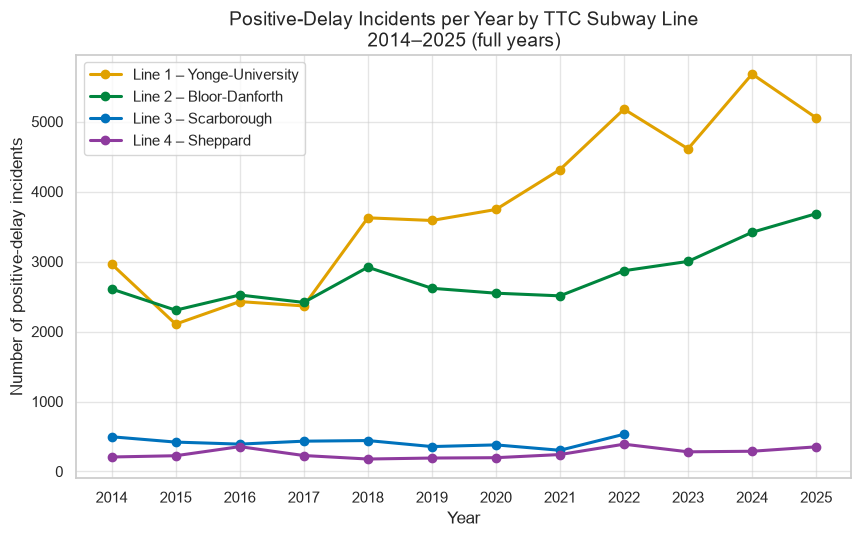

line_name,Line 1 – Yonge-University,Line 2 – Bloor-Danforth,Line 3 – Scarborough,Line 4 – Sheppard
year,,,,
2014,2964.0,2608.0,496.0,207.0
2015,2106.0,2305.0,420.0,225.0
2016,2428.0,2522.0,391.0,355.0
2017,2366.0,2416.0,433.0,228.0
2018,3625.0,2919.0,442.0,178.0
2019,3587.0,2618.0,356.0,192.0
2020,3744.0,2548.0,380.0,197.0
2021,4314.0,2510.0,303.0,242.0
2022,5178.0,2869.0,532.0,390.0


In [8]:
yearly = (positive[(positive["year"] <= 2025) & positive["line_name"].notna()]
          .groupby(["year", "line_name"]).size().unstack("line_name"))
yearly.loc[2023:, "Line 3 – Scarborough"] = np.nan        # Line 3 closed in July 2023: no line after 2022

fig, ax = plt.subplots(figsize=(10, 5.5))
for line_name, color in LINE_COLORS.items():
    ax.plot(yearly.index, yearly[line_name], marker="o", linewidth=2.2, color=color, label=line_name)
ax.set_title("Positive-Delay Incidents per Year by TTC Subway Line\n2014–2025 (full years)", fontsize=14)
ax.set_xlabel("Year")
ax.set_ylabel("Number of positive-delay incidents")
ax.set_xticks(yearly.index)
ax.legend()
save_and_show(fig, "01_delays_per_year.png")
display(yearly)

In [9]:
l1, l2 = "Line 1 – Yonge-University", "Line 2 – Bloor-Danforth"
print(f"Line 1: {yearly.loc[2014, l1]:,.0f} incidents in 2014 -> {yearly.loc[2025, l1]:,.0f} in 2025")
print(f"Line 2: {yearly.loc[2014, l2]:,.0f} incidents in 2014 -> {yearly.loc[2025, l2]:,.0f} in 2025")
print(f"Lowest year overall for Line 1: {yearly[l1].idxmin()} ({yearly[l1].min():,.0f})")

Line 1: 2,964 incidents in 2014 -> 5,054 in 2025
Line 2: 2,608 incidents in 2014 -> 3,684 in 2025
Lowest year overall for Line 1: 2015 (2,106)


**Interpretation.** Lines 1 and 2 have far more recorded delays than Lines 3 and 4, and the yearly counts on both lines are higher in 2025 than in 2014 (see the numbers above). Part of the difference between lines is size (Lines 1 and 2 are much longer and busier), and the dip around 2020–2021 coincides with the COVID-19 pandemic and with a change in how many zero-minute incidents were logged. These are possible explanations, not something the data prove.

### Chart 2 – Delay burden by line (Seaborn bar chart)
How many delay minutes does each line accumulate **per day**? To compare all four lines fairly we use 2014–2022, nine full years when all four lines were running.

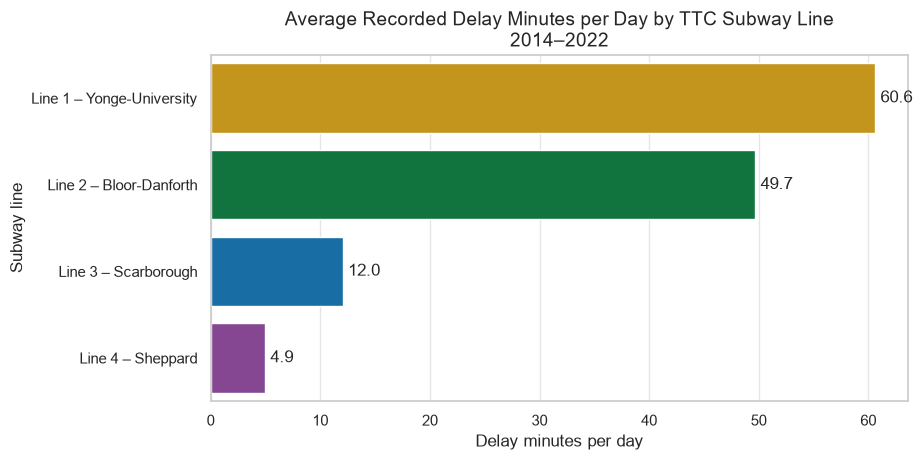

,line_name,minutes_per_day
0,Line 1 – Yonge-University,60.605415
1,Line 2 – Bloor-Danforth,49.670520
2,Line 3 – Scarborough,12.031336
3,Line 4 – Sheppard,4.943413


In [10]:
burden_period = positive[(positive["year"] <= 2022) & positive["line_name"].notna()]
days_in_period = (pd.Timestamp("2022-12-31") - pd.Timestamp("2014-01-01")).days + 1
minutes_per_day = (burden_period.groupby("line_name")["min_delay"].sum() / days_in_period).sort_values(ascending=False)
minutes_per_day = minutes_per_day.rename("minutes_per_day").reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=minutes_per_day, y="line_name", x="minutes_per_day", hue="line_name", palette=LINE_COLORS, legend=False, ax=ax)
for patch, value in zip(ax.patches, minutes_per_day["minutes_per_day"]):
    ax.text(value + 0.5, patch.get_y() + patch.get_height() / 2, f"{value:.1f}", va="center")
ax.set_title("Average Recorded Delay Minutes per Day by TTC Subway Line\n2014–2022", fontsize=14)
ax.set_xlabel("Delay minutes per day")
ax.set_ylabel("Subway line")
save_and_show(fig, "02_delay_minutes_per_day.png")
display(minutes_per_day)

In [11]:
top, bottom = minutes_per_day.iloc[0], minutes_per_day.iloc[-1]
print(f"{top['line_name']} accumulates {top['minutes_per_day']:.1f} delay minutes per day, "
      f"{top['minutes_per_day'] / bottom['minutes_per_day']:.1f} times {bottom['line_name']} ({bottom['minutes_per_day']:.1f}).")

Line 1 – Yonge-University accumulates 60.6 delay minutes per day, 12.3 times Line 4 – Sheppard (4.9).


**Interpretation.** The delay burden is highest on Line 1, followed by Line 2, and much lower on Lines 3 and 4. Because the lines differ in length, number of trains and passengers, this shows *where most delay minutes are recorded*, not which line is "worse" per trip or per passenger.

### Chart 3 – Leading causes of delay (Matplotlib horizontal bar chart)
Which delay codes account for the most delay minutes? We total `min_delay` per code (all lines, all years) and show the top 10 with their official descriptions.

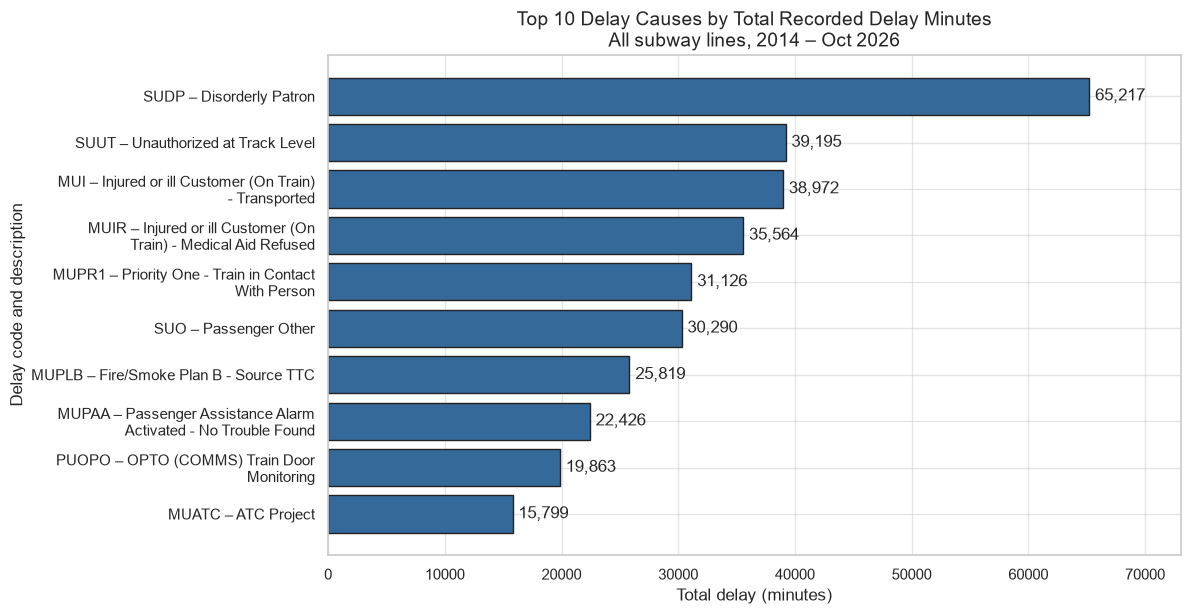

,total_minutes,incidents,share_of_all_minutes_pct,avg_minutes_per_incident
cause,,,,
SUDP – Disorderly Patron,65217,22959,9.4,2.8
SUUT – Unauthorized at Track Level,39195,4704,5.7,8.3
MUI – Injured or ill Customer (On Train) - Transported,38972,5297,5.6,7.4
MUIR – Injured or ill Customer (On Train) - Medical Aid Refused,35564,8080,5.1,4.4
MUPR1 – Priority One - Train in Contact With Person,31126,407,4.5,76.5
SUO – Passenger Other,30290,12184,4.4,2.5
MUPLB – Fire/Smoke Plan B - Source TTC,25819,1357,3.7,19.0
MUPAA – Passenger Assistance Alarm Activated - No Trouble Found,22426,17222,3.2,1.3
PUOPO – OPTO (COMMS) Train Door Monitoring,19863,6826,2.9,2.9


In [12]:
causes = (df.groupby("cause").agg(total_minutes=("min_delay", "sum"), incidents=("min_delay", "size"))
          .sort_values("total_minutes", ascending=False).head(10))
causes["share_of_all_minutes_pct"] = 100 * causes["total_minutes"] / df["min_delay"].sum()
causes["avg_minutes_per_incident"] = causes["total_minutes"] / causes["incidents"]

import textwrap
plot_data = causes.iloc[::-1]                       # reverse so the largest bar is at the top
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh([textwrap.fill(label, 40) for label in plot_data.index], plot_data["total_minutes"], color="#34699a", edgecolor="#222222")
for position, value in enumerate(plot_data["total_minutes"]):
    ax.text(value + 500, position, f"{value:,.0f}", va="center")
ax.set_title("Top 10 Delay Causes by Total Recorded Delay Minutes\nAll subway lines, 2014 – Oct 2026", fontsize=14)
ax.set_xlabel("Total delay (minutes)")
ax.set_ylabel("Delay code and description")
ax.set_xlim(0, plot_data["total_minutes"].max() * 1.12)
save_and_show(fig, "03_leading_delay_causes.png")
display(causes.round(1))

In [13]:
print(f"Top cause: {causes.index[0]} = {causes['share_of_all_minutes_pct'].iloc[0]:.1f}% of all delay minutes")
print(f"The top 10 causes together = {causes['share_of_all_minutes_pct'].sum():.1f}% of all delay minutes")
most_frequent = causes["incidents"].idxmax()
longest = causes["avg_minutes_per_incident"].idxmax()
print(f"Most frequent of the top 10: {most_frequent} ({causes.loc[most_frequent, 'incidents']:,} incidents)")
print(f"Longest on average: {longest} ({causes.loc[longest, 'avg_minutes_per_incident']:.1f} min per incident, only {causes.loc[longest, 'incidents']:,} incidents)")

Top cause: SUDP – Disorderly Patron = 9.4% of all delay minutes
The top 10 causes together = 46.8% of all delay minutes
Most frequent of the top 10: SUDP – Disorderly Patron (22,959 incidents)
Longest on average: MUPR1 – Priority One - Train in Contact With Person (76.5 min per incident, only 407 incidents)


**Interpretation.** The leading causes are mostly **passenger-related and emergency incidents** (for example disorderly patrons, ill or injured customers, people on the track) rather than equipment failures. A cause can rank high because it is *frequent* (many short delays) or because it is *severe* (few but long delays). The last two lines above show both types: the most frequent cause is not the one with the longest delays. Note that a code is the *reported* cause, not a verified root cause.

### Chart 4 – When do delays happen? (Seaborn heatmap)
Each cell counts the positive-delay incidents recorded at that hour of the day (columns) on that day of the week (rows), over the whole period.

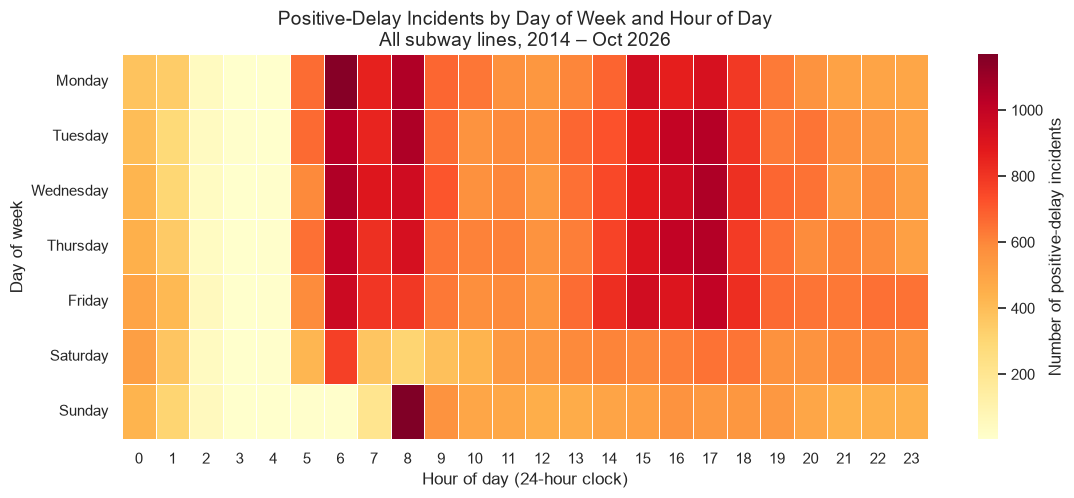

In [14]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat_data = (positive.groupby(["weekday", "hour"]).size().unstack("hour")
             .reindex(index=day_order, columns=range(24)).fillna(0))

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(heat_data, cmap="YlOrRd", linewidths=0.4, linecolor="white", ax=ax, cbar_kws={"label": "Number of positive-delay incidents"})
ax.set_title("Positive-Delay Incidents by Day of Week and Hour of Day\nAll subway lines, 2014 – Oct 2026", fontsize=14)
ax.set_xlabel("Hour of day (24-hour clock)")
ax.set_ylabel("Day of week")
ax.set_yticklabels(day_order, rotation=0)
save_and_show(fig, "04_delays_by_day_and_hour.png")

In [15]:
weekday_total = heat_data.loc[day_order[:5]].sum().sum() / 5
weekend_total = heat_data.loc[day_order[5:]].sum().sum() / 2
busiest_hours = heat_data.loc[day_order[:5]].sum().nlargest(3)
print(f"Average incidents per weekday-name: Mon-Fri {weekday_total:,.0f} vs Sat-Sun {weekend_total:,.0f}")
print("Busiest weekday hours:", {f"{hour}:00": int(count) for hour, count in busiest_hours.items()})
print(f"Incidents between 02:00 and 04:59: {int(heat_data.loc[:, 2:4].sum().sum()):,}")

Average incidents per weekday-name: Mon-Fri 14,714 vs Sat-Sun 10,483
Busiest weekday hours: {'6:00': 5199, '17:00': 5070, '8:00': 4791}
Incidents between 02:00 and 04:59: 391


**Interpretation.** Recorded delays are concentrated on **weekdays**, especially around the **morning start (about 06:00–08:59) and the late afternoon (about 15:00–18:59)**, and there are almost none between 02:00 and 05:00 when the subway is mostly closed. Weekends show lower counts. These are *counts*, not risk: rush hours have more trains and passengers, so more incidents there does not by itself prove that a trip is more likely to be delayed then.

## 7. Conclusions

* **Which lines?** Lines 1 and 2 record far more delays and delay minutes than Lines 3 and 4 (Chart 1 and Chart 2), and the recorded delays on Lines 1 and 2 have grown since 2014.
* **Which causes?** Passenger-related and emergency incidents account for the largest share of delay minutes (Chart 3); rare serious events last far longer than frequent minor ones.
* **When?** Delays are recorded mainly on weekdays during the commute hours (Chart 4).

**Limitations.** The data record *incidents*, not passengers or scheduled trips, so the charts cannot show the probability that a trip is delayed. Lines differ in length and frequency; Line 3 closed in July 2023; the COVID-19 pandemic changed service in 2020–2021; and the way incidents are logged appears to have changed around 2020. About 2 % of records use a combined or unrecognised line name and are left out of the per-line charts, and some delay codes in the data are not in the supplied code table.

**Why visualization helps.** The charts turn about 273,000 table rows into four simple pictures that show where, why and when delays are recorded, which would be difficult to see in the raw data.

## 8. References

City of Toronto Open Data. (n.d.). *TTC subway delay data* [Data set]. City of Toronto. https://open.toronto.ca/dataset/ttc-subway-delay-data/

Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

Python Software Foundation. (n.d.). *Python 3 documentation*. https://docs.python.org/3/

Toronto Transit Commission. (n.d.). *Line 3 Scarborough permanently closed*. https://ttc.ca/riding-the-ttc/Updates/Line-3-Scarborough-permanently-closed

Waskom, M. L. (n.d.). *seaborn: Statistical data visualization*. https://seaborn.pydata.org/